# <RIG> — Measurement (rig base)

Device-agnostic measure skeleton for the **VTI** rig. `hera-mksession` copies
this per session; **hera-session** fills the device-specific cells (tagged
`metadata.hera.slot`) from `device_card.md` and marks every filled value
`# <-- validate` for the operator to check.

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
hera-session-filled) line at bring-up. Cells marked **PATTERN** / **PROPOSAL**
carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep

from hera.analysis import GateCalibration

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205
from drivers.async_station import async_station

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260619-QC0426'

# Connect Instruments

## Magnet

In [3]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.003 Tesla
Current:             : 0.019 A
Voltage:             : -0.000 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [4]:
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')  # <-- verify address
print(heater.sample_temperature())
print(heater.vaporizer_temperature())

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.12s
1.163
0.0


## Lock-ins

In [5]:
sr0 = SR830('sr0', "GPIB0::17::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.11s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.09s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr2 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [6]:
k_2400 = Keithley_2400('k_2400', 'GPIB0::24::INSTR')  # <-- verify address — back-gate Keithley
k_2400.mode.set('VOLT')
k_2400.volt.set(0)
k_2400.rangei.set(1e-6)
k_2400.rangev.set(21)
k_2400.volt.step = 0.005
k_2400.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.03s


In [7]:
k_2410 = Keithley_2400('k_2410', 'GPIB0::25::INSTR')  # <-- verify address — Si-gate Keithley
k_2410.mode.set('VOLT')
k_2410.volt.set(0)
k_2410.rangei.set(1e-6)
k_2410.rangev.set(21)
k_2410.volt.step = 0.005
k_2410.volt.inter_delay = 0.01  # Si gate dV/dt pacing - dielectric safety
k_2410.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2410 (serial:1293333, firmware:C30   Mar 17 2006 09:29:29/A02  /J/J) in 0.03s


## DC205 (top gate)

In [8]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — top-gate DC205
dc205.ramp_rate = 2  # V/s

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.02s


In [9]:
# slot: gate-bindings. hera-session fills the role aliases from the device
# card's wiring (which instrument drives which gate). Mark each filled line
# `# <-- validate`. The dc205_volt wrapper is generic; the k_* role map is
# device-specific. PLACEHOLDER mapping below is the QC0426 wiring.

# Sweepable top-gate parameter — appears in the data as column 'DC_bias'.
def dcbias(vg):
    dc205.ramp_voltage(vg)

dc205_volt = qcodes.Parameter('DC_bias', unit='V', set_cmd=dcbias)

# Gate role aliases (recipes use k_tg / k_bg / k_si):
k_tg = dc205_volt   # top gate <- DC205 (fast axis is dc205_volt, NOT k_tg.volt)   # <-- validate
k_bg = k_2400       # back gate <- Keithley 2400                                     # <-- validate
k_si = k_2410       # Si gate   <- Keithley 2410                                     # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [10]:
# slot: gate-validators. hera-session fills the operating limits from the
# device card's gate-operating-limits table; commit EXACTLY the card numbers.
# Mark each filled value `# <-- validate`. PLACEHOLDER numbers below.
# Instrument-level fences go on the RAW instruments (dc205 / k_2400 / k_2410);
# direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -6.0, +7.0    # top gate (dc205_volt), V    # <-- validate
BG_MIN, BG_MAX = -4.5, +4.5    # back gate (k_2400), V        # <-- validate
SI_MIN, SI_MAX = -50.0, +50.0  # Si gate (k_2410), V          # <-- validate
dc205_volt.vals = validators.Numbers(TG_MIN, TG_MAX)
dc205.voltage.vals = validators.Numbers(TG_MIN, TG_MAX)  # instrument-level: direct dc205 calls bypass dc205_volt
k_2400.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
k_2410.volt.vals = validators.Numbers(SI_MIN, SI_MAX)

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.mag is a qcodes Parameter,
# so this validator rejects any magnet.mag(target) with |B| > B_SESSION_CAP
# before any hardware traffic. (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 8.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.mag.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — TYPO GUARD ONLY (sample_setpoint(3000) vs 300).
# The real safe T/B envelope is a rig-card item.
T_SESSION_CAP = 310.0  # K    # <-- verify
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)

# Helpers

In [11]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [12]:
# slot: geometry. hera-session fills the gate-stack thicknesses from the
# device card (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Mark each filled value `# <-- validate`.
# PLACEHOLDER numbers below.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [13]:
# slot: meas-config. hera-session fills sr0_gain and the channel/contact
# assignments from the device card (current channel + gain, provided contact
# configuration). Mark each filled value `# <-- validate`. Always set
# 'comments' per run — structured, current, no inherited text.
meas_config = {
    "sr0": "drain current on B7",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "T3-T4",  # <-- validate
    "sr2": "B4-B5",  # <-- validate
    "sr3": "T5-B6",  # <-- validate
    "bias_resistor": 100e6,
    "bias_voltage": sr1.amplitude(),
    "lockin_freq": sr1.frequency(),
    "sr0_sens": sr0.sensitivity(),
    "sr1_sens": sr1.sensitivity(),
    "sr2_sens": sr2.sensitivity(),
    "sr3_sens": sr3.sensitivity(),
    "sample_temperature:": heater.sample_temperature(),  # key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": k_2410.volt(),
    "comments": "<SET PER RUN>",
}

## QSwitch (contact mux) — LIVE

Contact-mux bring-up and the line/breakout maps are device-specific — see the
device card's contact-map section; hera-session fills the cell below from it.
`qsw.reset()` is **always forbidden** — it opens the Si standing closures and
drops the Si gate.

In [14]:
from drivers.QSwitch import QSwitch
from drivers.contact_mux import ContactMux

qsw = QSwitch('qswitch', 'ASRL4::INSTR')  # <-- verify address — QSwitch

# Contact label -> QSwitch line. Si standing-closure lines are EXCLUDED.
LINES = {  # <-- validate (from card contact map)
    "T1": 1,  "T2": 3,  "T3": 4,  "T4": 6,  "T5": 7,  "T6": 12, "T7": 13,
    "B1": 8,  "B2": 17, "B3": 23, "B4": 22, "B5": 20, "B6": 19, "B7": 18, "B8": 15,
}
# Instrument port -> front-panel BNC tap.
BREAKOUTS = {  # <-- validate (from card instrument taps)
    "source": 7, "drain": 8,
    "sr1+": 1, "sr1-": 2, "sr2+": 3, "sr2-": 4, "sr3+": 5, "sr3-": 6,
}
SETTLE_S = 4  # <-- validate (calibrated relay settle)

mux = ContactMux(qsw, lines=LINES, breakouts=BREAKOUTS, settle_s=SETTLE_S)
# qsw.reset() ALWAYS FORBIDDEN — drops the Si gate (standing closures).

Connected to: Quantum Machines QSwitch (serial:37, firmware:2.0) in 0.05s


## HERA — bring-up VERIFY readback (gate A/B)

Read-only; no instrument writes. Confirms: magnet at 0 T, base T, committed
validators vs device-card limits (TG[-6,7] BG[-4.5,4.5] Si[-50,50] B[-8,8]),
lock-in tau/filter-slope (record at bring-up per rig card), AC drive, and the
standing gate values. Run and I will compare against the card before the grant.

In [15]:
# Bring-up VERIFY readback (read-only). HERA gate A/B confirm.
print('== Magnet ==')
print('  mag() measured T:', magnet.mag())
print('  _status:', magnet._status())
print('== Thermometry ==')
print('  sample_temperature K:', heater.sample_temperature())
print('  vaporizer_temperature K:', heater.vaporizer_temperature())
print('== Lock-in tau / filter_slope / sens ==')
for nm, sr in [('sr0', sr0), ('sr1', sr1), ('sr2', sr2), ('sr3', sr3)]:
    print('  ', nm, 'tau_s=', sr.time_constant(), 'slope=', sr.filter_slope(), 'sens=', sr.sensitivity())
print('== AC drive (sr1) ==')
print('  amplitude V:', sr1.amplitude(), 'freq Hz:', sr1.frequency())
print('== Committed validators (expect TG[-6,7] BG[-4.5,4.5] Si[-50,50] B[-8,8]) ==')
print('  dc205_volt.vals  :', dc205_volt.vals)
print('  dc205.voltage.vals:', dc205.voltage.vals)
print('  k_2400.volt.vals :', k_2400.volt.vals)
print('  k_2410.volt.vals :', k_2410.volt.vals)
print('  magnet.mag.vals  :', magnet.mag.vals)
print('== Standing gate values ==')
print('  TG dc205.voltage() V:', dc205.voltage())
print('  BG k_2400.volt()  V:', k_2400.volt())
print('  Si k_2410.volt()  V:', k_2410.volt())

== Magnet ==
  mag() measured T: 0.002528109589041096
  _status: {'voltage': -6.13e-05, 'field': 0.0025259999999999996, 'output_enabled': True, 'persistent_switch_on': True, 'loop_mode': 'CC', 'update_mode': 'NORMAL'}
== Thermometry ==
  sample_temperature K: 1.164
  vaporizer_temperature K: 0.0
== Lock-in tau / filter_slope / sens ==
   sr0 tau_s= 0.1 slope= 24 sens= 0.1
   sr1 tau_s= 0.03 slope= 24 sens= 2e-05
   sr2 tau_s= 0.3 slope= 24 sens= 2e-05
   sr3 tau_s= 0.3 slope= 24 sens= 5e-05
== AC drive (sr1) ==
  amplitude V: 0.5 freq Hz: 13.0
== Committed validators (expect TG[-6,7] BG[-4.5,4.5] Si[-50,50] B[-8,8]) ==
  dc205_volt.vals  : <Numbers -6.0<=v<=7.0>
  dc205.voltage.vals: <Numbers -6.0<=v<=7.0>
  k_2400.volt.vals : <Numbers -4.5<=v<=4.5>
  k_2410.volt.vals : <Numbers -50.0<=v<=50.0>
  magnet.mag.vals  : <Numbers -8.0<=v<=8.0>
== Standing gate values ==
  TG dc205.voltage() V: 0.0
  BG k_2400.volt()  V: 0.0
  Si k_2410.volt()  V: 0.0


## HERA [E1] — kernel-binding probe (first autonomous execute)

Read-only. Confirms nb-collab's execute path is bound to the operator's
instrument-carrying kernel (names resolve to the live instruments, magnet/T
read back), not a fresh kernel. No instrument writes.

In [16]:
# Kernel-binding probe (read-only). HERA first E1 execute.
names = ['magnet','heater','sr0','sr1','sr2','sr3','k_2400','k_2410','dc205','dc205_volt','mux','qsw','meas_config']
present = [n for n in names if n in globals()]
missing = [n for n in names if n not in globals()]
print('present :', present)
print('missing :', missing)
print('kernel pid:', os.getpid())
print('magnet id / mag T:', hex(id(magnet)), magnet.mag())
print('sample T K:', heater.sample_temperature())
print('mux type:', type(mux).__name__, '| qsw type:', type(qsw).__name__)

present : ['magnet', 'heater', 'sr0', 'sr1', 'sr2', 'sr3', 'k_2400', 'k_2410', 'dc205', 'dc205_volt', 'mux', 'qsw', 'meas_config']
missing : []
kernel pid: 42556
magnet id / mag T: 0x14c6fd26330 0.0025443150684931505
sample T K: 1.163
mux type: ContactMux | qsw type: QSwitch


## HERA [E1] — gate C: contact-config liveness (provided configuration)

First-session branch (no designated references): confirm the provided contacts
are alive before committing the 0 T gate map. Select the provided config (T2 src
/ B7 drain / sr1 T3-T4 / sr2 B4-B5 / sr3 T5-B6 Hall) and read 4-terminal R at the
operating point (all gates 0 V, B=0). Auto: routing inside the managed line set
(16/11 Si closures untouched), reversible, no sweep. Precondition: T=1.16 K, B~0,
gates 0 — all confirmed by the probe above. Expect finite, sane R on the live
pairs; a railed or near-zero channel flags a dead contact.

In [17]:
# Gate C liveness — select provided config, read 4-terminal R at operating point.
mux.select({'source': 'T2', 'drain': 'B7', 'sr1+': 'T3', 'sr1-': 'T4',
            'sr2+': 'B4', 'sr2-': 'B5', 'sr3+': 'T5', 'sr3-': 'B6'})
Ibias = meas_config['bias_voltage'] / meas_config['bias_resistor']
Vsr0 = sr0.X()
I_meas = Vsr0 / meas_config['sr0_gain']
print('gates TG/BG/Si V:', dc205.voltage(), k_2400.volt(), k_2410.volt(), '| B T:', magnet.mag())
print('I_bias nominal nA:', round(Ibias*1e9, 4))
print('I_meas drain nA  :', round(I_meas*1e9, 4), '(sr0.X V=', Vsr0, ')')
for nm, sr in [('sr1 T3-T4', sr1), ('sr2 B4-B5', sr2), ('sr3 T5-B6 Hall', sr3)]:
    Vx = sr.X()
    R = (Vx / I_meas) if I_meas not in (0.0,) else float('nan')
    print(f'  {nm:16s} X(V)={Vx: .6e}  R(kOhm)={R/1e3: .3f}')

gates TG/BG/Si V: 0.0 0.0 0.0 | B T: 0.0025944109589041094
I_bias nominal nA: 5.0
I_meas drain nA  : 4.9324 (sr0.X V= -0.00493243 )
  sr1 T3-T4        X(V)= 7.324880e-06  R(kOhm)= 1.485
  sr2 B4-B5        X(V)= 3.775600e-06  R(kOhm)= 0.765
  sr3 T5-B6 Hall   X(V)= 1.491990e-06  R(kOhm)= 0.302


## HERA [E1] — leakage-monitor probe (read-only)

Confirm BG/Si Keithley current readbacks are gettable before wiring them into
the gate-map fp list (DC205 top gate has no current monitor). Read-only.

In [18]:
print('k_bg(=k_2400).curr A:', k_2400.curr())
print('k_si(=k_2410).curr A:', k_2410.curr())
print('k_bg.volt:', k_2400.volt(), ' k_si.volt:', k_2410.volt())

k_bg(=k_2400).curr A: 1.22367e-10
k_si(=k_2410).curr A: -3.52131e-11


k_bg.volt: 0.0  k_si.volt: 0.0


## HERA [E1] — recon: 1D TG line-cut @ BG=0 (CNP locate + leakage/settling)

Cheap-first before the 2D map: sweep TG over the full [-6,7] V range at BG=0,
Si=0, B=0 to (a) locate the CNP in the TG window, (b) confirm TG ramps to its
extremes without misbehavior, (c) read ridge sharpness + sr2/sr3 settling on real
data to price the map dwell. 131 pts, delay=2.0 s (settles sr2/sr3 tau=0.3 s);
~4.5 min. Leakage via Keithley curr (DC205 has no monitor); NO per-point Lakeshore
poll (rig quirk). Tag 'gatemap'. Precondition asserts T/B/Si at top.

precond: T=1.163 K (exp ~1.16)  B=0.0026 T (exp ~0)  BG=0.000  Si=0.000
2026-06-18 22:46:09,454 [INFO] Ramping k_2400_volt: 0.0 -> 0.0


2026-06-18 22:46:09,462 [INFO] Ramping DC_bias: None -> -6.0


2026-06-18 22:46:13,523 [INFO] Starting sweep with ID 0


2026-06-18 22:46:13,523 [INFO] Minimum duration 0h 4m 22s


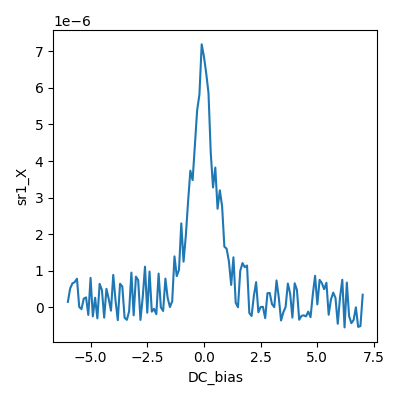

2026-06-18 22:51:09,393 [INFO] Completed in 0h 4m 55s


2026-06-18 22:51:09,393 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260619-QC0426\data\0\data.tsv.gz


2026-06-18 22:51:09,394 [INFO] Ramping DC_bias: 7.0 -> 0.0


recon done; T_end=1.163 K


In [19]:
import numpy as np, time
# --- preconditions (state this cut assumes but does not set) ---
T0 = heater.sample_temperature(); B0 = magnet.mag()
print('precond: T=%.3f K (exp ~1.16)  B=%.4f T (exp ~0)  BG=%.3f  Si=%.3f' % (T0, B0, k_2400.volt(), k_2410.volt()))
assert T0 < 2.0, 'T unexpectedly high'
assert abs(B0) < 0.05, 'B not at zero'
assert abs(k_2410.volt()) < 1e-6, 'Si not at 0'
# --- station (fresh comments) ---
meas_config['comments'] = 'recon 1D TG cut @ BG=0,Si=0,B=0; CNP locate + leakage/settling; T_start=%.3f K' % T0
s = async_station(meas_config)
s.add_comment('gatemap')
s.add_comment(meas_config['comments'])
# leakage monitors (Keithleys only; NOT Lakeshore -- rig quirk)
s.fp(k_2400.curr); s.fp(k_2410.curr)
# lock-ins: RAW X and P (gains live in metadata)
for sr in (sr0, sr1, sr2, sr3):
    s.fp(sr.X); s.fp(sr.P)
s.plot(dc205_volt, sr1.X)
# operating point + start field/gates
s.ramp(k_2400.volt, 0.0)        # BG -> 0 (already 0)
s.ramp(dc205_volt, -6.0)        # TG -> start (blocking ramp)
time.sleep(1)
tg_vec = spoints(-6.0, 7.0, 131)  # 0.1 V step
s.sweep(dc205_volt, tg_vec, delay=2.0)
s.ramp(dc205_volt, 0.0)         # park TG
print('recon done; T_end=%.3f K' % heater.sample_temperature())

## HERA [E1] — 0 T TG–BG gate map (CNP-line calibration + clean-region survey)

Full-box megasweep: **BG slow rows** `linspace(-4.5,4.5,37)` (Δ0.25 V) × **TG fast**
`linspace(-6,7,131)` (Δ0.10 V), Si=0, B=0. BG-slow/TG-fast so the fitted ridge
position is V_tg vs V_bg rows → slope = −c_bg/c_tg directly (cnp-and-dline recipe).
Box brackets the recon CNP at (0,0) with geometry slope −1.3 → CNP line runs
V_tg≈+5.85 (BG −4.5) → −5.85 (BG +4.5), fully inside the TG window.

**Settling:** `fast_delay=1.0` — recon validated the ridge at delay 2.0; sr1 (τ=0.03)
is fully settled, sr2/sr3 (τ=0.3) lag ≈0.03 V (< Δ_TG), negligible for ridge *position*
(I fit sr1 primary). `slow_delay=2.0`. **~1.5 h** (37 rows × 131 pts × ~1.05 s + retrace).

**Checkpoint @ ~28 min (≈row 11, BG≈−1.75 V):** confirm the ridge is tracking
diagonally at slope ≈−1.3 (CNP should sit near V_tg≈+2.3 there), BG leakage < few
hundred pA, lock-ins not flat/railed. Fork: continue / adjust extent / abort. Leakage
via Keithley `curr` (DC205 has no monitor); NO per-point Lakeshore poll (rig quirk).
Auto: all gates inside committed validators, reversible. Tag 'gatemap'.


precond: T=1.163 K  B=0.0026 T  BG=0.000  Si=0.000
2026-06-18 22:57:24,265 [INFO] Ramping k_2400_volt: 0.0 -> -4.5


2026-06-18 22:57:30,038 [INFO] Ramping DC_bias: 0.0 -> -6.0


2026-06-18 22:57:34,104 [INFO] Starting megasweep with ID 1


2026-06-18 22:57:34,105 [INFO] Minimum duration 1h 22m 1s


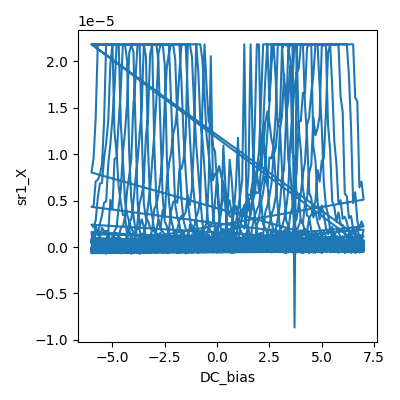

2026-06-19 00:44:23,070 [INFO] Completed in 1h 46m 48s


2026-06-19 00:44:23,071 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260619-QC0426\data\1\data.tsv.gz


2026-06-19 00:44:23,073 [INFO] Ramping DC_bias: 7.0 -> 0.0


2026-06-19 00:44:26,769 [INFO] Ramping k_2400_volt: 4.5 -> 0.0


gatemap done; T_end=1.163 K


In [20]:
import numpy as np, time
# --- preconditions (state this map assumes but does not set) ---
T0 = heater.sample_temperature(); B0 = magnet.mag()
print('precond: T=%.3f K  B=%.4f T  BG=%.3f  Si=%.3f' % (T0, B0, k_2400.volt(), k_2410.volt()))
assert T0 < 2.0, 'T high'
assert abs(B0) < 0.05, 'B not zero'
assert abs(k_2410.volt()) < 1e-6, 'Si not 0'
# --- station (fresh comments) ---
meas_config['comments'] = ('0T TG-BG gatemap; BG rows slow / TG fast; Si=0 B=0; '
                           'CNP-line + clean-region survey; T_start=%.3f K' % T0)
s = async_station(meas_config)
s.add_comment('gatemap')
s.add_comment(meas_config['comments'])
# leakage monitors (Keithleys only; NOT Lakeshore -- rig quirk)
s.fp(k_2400.curr); s.fp(k_2410.curr)
# lock-ins: RAW X and P (gains live in metadata for hera-watch/analysis)
for sr in (sr0, sr1, sr2, sr3):
    s.fp(sr.X); s.fp(sr.P)
s.plot(dc205_volt, sr1.X)
# ramp to start of box
s.ramp(k_2400.volt, -4.5)     # BG slow start
s.ramp(dc205_volt, -6.0)      # TG fast start (blocking)
time.sleep(1)
bg_vec = spoints(-4.5, 4.5, 37)    # slow rows, 0.25 V
tg_vec = spoints(-6.0, 7.0, 131)   # fast, 0.10 V
s.megasweep(k_2400.volt, bg_vec, dc205_volt, tg_vec, slow_delay=2.0, fast_delay=1.0)
# park gates
s.ramp(dc205_volt, 0.0); s.ramp(k_2400.volt, 0.0)
print('gatemap done; T_end=%.3f K' % heater.sample_temperature())


## HERA [E1] — SdH spot-check A: HOLE side, n=−10e12 cm⁻², D=0

Step 3 of `trilayer-stacking-fs-count` (`sdh-spot-check`). Fixed (n, D=0), B swept
**0→4 T** from zero (captures onset), ΔB=10 mT (401 pts). F_L=103 T → ΔB Nyquists down
to ~1.7 T; recipe-validated step (scales from corpus 12.5 mT@8e12). Gates set to
(V_tg −4.666, V_bg −3.616) on the calibrated D=0 line. Magnet's built-in 3 s/point dwell
settles all lock-ins (even sr2/sr3 τ=0.3 → 10τ); leave operator τ untouched. ~52 min
(ramp + 3 s/pt dominated). Leakage via Keithley curr; T in comment (no Lakeshore poll).

**Checkpoint @ ~25 min (B≈2 T):** SdH oscillations emerging? onset visible? which Rxx
channel cleanest? leakage clean? Fork: continue / extend B / abort. Read is the 1/B FFT
(scratch, TSV) after completion. Ends at B=4 T (electron spot check will run 4→0 to reuse
the ramp-down — no dead re-traverse). Auto: gates in validators, B≤4<8 cap. Tag `sdh-spot-check`.


precond: T=1.163 K  B=0.0026 T  BG=1.125  Si=0.000
2026-06-19 00:56:42,203 [INFO] Ramping k_2400_volt: 0.5625 -> -3.616


2026-06-19 00:56:47,552 [INFO] Ramping DC_bias: 0.0 -> -4.666


at target: TG=-4.666 BG=-2.431  I_drain=5.047 nA
2026-06-19 00:56:52,129 [INFO] Starting sweep with ID 2


2026-06-19 00:56:52,130 [INFO] Minimum duration 0h 3m 20s


2026-06-19 01:24:11,916 [WARNING] ID 2 INTERRUPTED


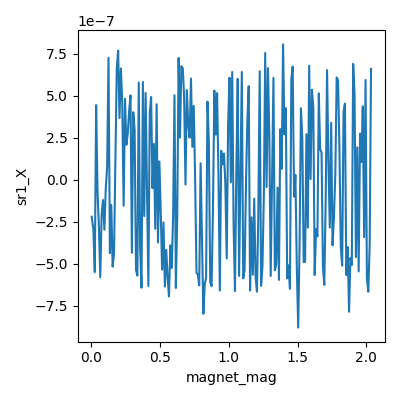

2026-06-19 01:24:12,465 [INFO] Completed in 0h 27m 19s


2026-06-19 01:24:12,465 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260619-QC0426\data\2\data.tsv.gz


spot A done; B=2.035 T  T_end=1.198 K


In [21]:
import numpy as np, time
# --- preconditions ---
T0 = heater.sample_temperature(); B0 = magnet.mag()
print('precond: T=%.3f K  B=%.4f T  BG=%.3f  Si=%.3f' % (T0, B0, k_2400.volt(), k_2410.volt()))
assert T0 < 2.0, 'T high'
assert abs(B0) < 0.05, 'B not ~0 (spot check must start near 0 for onset)'
assert abs(k_2410.volt()) < 1e-6, 'Si not 0'
# --- target: hole n=-10e12 cm^-2 at D=0 ---
VTG, VBG = -4.666, -3.616
meas_config['comments'] = ('SdH spot-check HOLE n=-10e12 cm^-2 D=0 (V_tg=%.3f V_bg=%.3f); '
                           'B 0->4T dB=10mT; onset + tone content; T_start=%.3f K' % (VTG, VBG, T0))
s = async_station(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(meas_config['comments'])
s.fp(magnet.mag)                 # measured field per point (for 1/B FFT)
s.fp(k_2400.curr); s.fp(k_2410.curr)
for sr in (sr0, sr1, sr2, sr3):
    s.fp(sr.X); s.fp(sr.P)
s.plot(magnet.mag, sr1.X)
# ramp gates to (n=-10e12, D=0) at B=0
s.ramp(k_2400.volt, VBG)
s.ramp(dc205_volt, VTG)
time.sleep(2)
print('at target: TG=%.3f BG=%.3f  I_drain=%.3f nA' % (dc205.voltage(), k_2400.volt(), sr0.X()/(-1e6)*1e9))
field = np.arange(0.0, 4.0 + 1e-9, 0.010)   # 0..4 T, 10 mT step (401 pts)
s.sweep(magnet.mag, field, delay=0.5)
print('spot A done; B=%.3f T  T_end=%.3f K' % (magnet.mag(), heater.sample_temperature()))


## HERA [E1] — recovery: set lock-in sensitivity for high-n SdH

Spot-check A was under-ranged (sens 2e-5 = CNP-tuned; signal ~0.25% FS on the ~tens-Ω
metallic Rxx). Per sdh-spot-check Step 3 (full scale ~ I_bias*R_target): set sr1/sr2
(Rxx) to 1e-6, sr3 (Hall, R_xy->~250 Ohm at 4T) to 5e-6, sr0 (current) to 1e-2. Read R
back at the new range to confirm %FS. State re-read after the abort (B, gates). Auto.

In [22]:
import numpy as np, time
print('post-abort state: B=%.3f T  TG=%.3f BG=%.3f Si=%.3f  T=%.3f K' % (magnet.mag(), dc205.voltage(), k_2400.volt(), k_2410.volt(), heater.sample_temperature()))
sr0.sensitivity(1e-2); sr1.sensitivity(1e-6); sr2.sensitivity(1e-6); sr3.sensitivity(5e-6)
time.sleep(2)
I = sr0.X()/meas_config['sr0_gain']
for nm,sr in [('sr1',sr1),('sr2',sr2),('sr3',sr3)]:
    x=sr.X(); print('  %s: X=%.3e V  R=%.1f Ohm  sens=%.0e  %.1f%%FS' % (nm, x, x/I, sr.sensitivity(), abs(x)/sr.sensitivity()*100))
print('  I_drain=%.3f nA  sr0 %.1f%%FS' % (I*1e9, abs(sr0.X())/sr0.sensitivity()*100))
for k,sr in [('sr0_sens',sr0),('sr1_sens',sr1),('sr2_sens',sr2),('sr3_sens',sr3)]:
    meas_config[k]=sr.sensitivity()
print('meas_config sens updated')

post-abort state: B=2.033 T  TG=-4.666 BG=-3.616 Si=0.000  T=1.198 K


  sr1: X=-1.930e-07 V  R=-38.5 Ohm  sens=1e-06  19.3%FS
  sr2: X=3.033e-08 V  R=6.1 Ohm  sens=1e-06  3.0%FS
  sr3: X=-9.988e-08 V  R=-19.9 Ohm  sens=5e-06  2.0%FS
  I_drain=5.011 nA  sr0 49.2%FS
meas_config sens updated


## HERA [E1] — lock-in phase/offset diagnostic (high-n hole point, B=2 T)

Negative sr1 R and small Hall: read X, Y, R(magnitude), phase per channel to see if
signal is in X (sign=convention, OK) or phase/offset needs fixing before re-run. Read-only.

In [23]:
I = sr0.X()/meas_config['sr0_gain']
print('I_drain=%.3f nA  B=%.3f T  (n~-10e12 hole)' % (I*1e9, magnet.mag()))
for nm,sr in [('sr1 T3-T4',sr1),('sr2 B4-B5',sr2),('sr3 Hall',sr3)]:
    X,Y,R,P = sr.X(), sr.Y(), sr.R(), sr.P()
    print('  %-10s X=%+.3e Y=%+.3e  |R|=%.3e V  phase=%+6.1f deg  -> |R|/I=%.1f Ohm  X/I=%+.1f Ohm' % (nm, X, Y, R, P, R/abs(I), X/I))

I_drain=4.976 nA  B=2.033 T  (n~-10e12 hole)
  sr1 T3-T4  X=-7.381e-08 Y=+1.265e-07  |R|=6.019e-07 V  phase=-174.2 deg  -> |R|/I=121.0 Ohm  X/I=-14.8 Ohm
  sr2 B4-B5  X=-5.035e-08 Y=-5.227e-08  |R|=6.915e-08 V  phase=-126.5 deg  -> |R|/I=13.9 Ohm  X/I=-10.1 Ohm
  sr3 Hall   X=-3.865e-07 Y=+1.164e-08  |R|=3.863e-07 V  phase=+177.2 deg  -> |R|/I=77.6 Ohm  X/I=-77.7 Ohm


## HERA [E1] — stable lock-in magnitude estimate (8 reads)

Sequential X/Y/R were inconsistent (noisy, sr1 tau=0.03). Read |R| 8x per channel for a
stable magnitude + phase spread, to pick per-channel sensitivity and judge whether phase/tau
need operator tuning. Read-only, gates held at hole n=-10e12, B=2 T.

In [24]:
import numpy as np, time
I = abs(sr0.X()/meas_config['sr0_gain'])
for nm,sr in [('sr1 T3-T4',sr1),('sr2 B4-B5',sr2),('sr3 Hall',sr3)]:
    Rs=[]; Ps=[]
    for _ in range(8):
        Rs.append(sr.R()); Ps.append(sr.P()); time.sleep(0.3)
    Rs=np.array(Rs); Ps=np.array(Ps)
    print('  %-10s |R|/I = %6.1f +- %4.1f Ohm   phase %+6.1f +- %4.1f deg   tau=%.3f' % (
        nm, np.mean(Rs)/I, np.std(Rs)/I, np.mean(Ps), np.std(Ps), sr.time_constant()))
print('I_drain=%.3f nA  B=%.3f T' % (I*1e9, magnet.mag()))

  sr1 T3-T4  |R|/I =  127.5 +- 17.6 Ohm   phase   -9.6 +- 102.4 deg   tau=0.030


  sr2 B4-B5  |R|/I =   25.9 +-  3.4 Ohm   phase  +42.4 +- 22.7 deg   tau=0.300


  sr3 Hall   |R|/I =   90.9 +- 28.2 Ohm   phase  +44.7 +- 168.2 deg   tau=0.300
I_drain=4.953 nA  B=2.033 T


## HERA [E1] — SdH spot-check A (re-run): proper sensitivity + magnitude readout

First attempt was under-ranged (sens 2e-5 from the kΩ CNP map → 0.25% FS on the ~tens-Ω
metallic Rxx; aborted at 2 T, data/2). Fix: per-channel sens for Rxx~tens-Ω (sr1 2e-6
[|R|~128 Ω], sr2 5e-7 [|R|~26 Ω, cleanest], sr3 5e-6 Hall, sr0 1e-2); raise sr1 τ 0.03→0.3.
Diagnostic showed the resistive signal at ~+42° — a cosmetic **reference-phase offset**
(device is resistive at 13 Hz), so **Rxx = lock-in |R|**; fp X/Y/R and use the magnitude
(phase handled offline), leaning on the cleaner sr2.

B 0→4 T, ΔB=10 mT (first point ramps 2→0). ~70 min (incl. the 2→0 down-ramp). Ends at
4 T for the electron spot check (4→0). Checkpoint ~30 min in. Auto: gates in validators,
B≤4<8 cap. Tag `sdh-spot-check`.


pre: B=2.033 T  TG=-4.666 BG=-3.616 Si=0.000  T=1.198 K


2026-06-19 01:31:39,981 [INFO] Starting sweep with ID 3


2026-06-19 01:31:39,982 [INFO] Minimum duration 0h 3m 20s


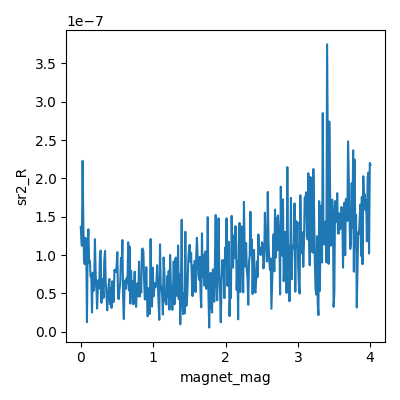

2026-06-19 02:40:21,698 [INFO] Completed in 1h 8m 40s


2026-06-19 02:40:21,698 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260619-QC0426\data\3\data.tsv.gz


spot A v2 done; B=4.005 T  T_end=1.231 K


In [25]:
import numpy as np, time
# --- preconditions: gates still at hole density, magnet at ~2 T (sweep ramps it to 0) ---
T0 = heater.sample_temperature()
print('pre: B=%.3f T  TG=%.3f BG=%.3f Si=%.3f  T=%.3f K' % (magnet.mag(), dc205.voltage(), k_2400.volt(), k_2410.volt(), T0))
assert abs(dc205.voltage()-(-4.666)) < 0.05 and abs(k_2400.volt()-(-3.616)) < 0.05, 'gates not at hole n=-10e12'
assert abs(k_2410.volt()) < 1e-6, 'Si not 0'
# --- lock-in config for high-n metallic SdH (Rxx ~tens of Ohm) ---
sr1.time_constant(0.3)              # was 0.03 (too noisy); match sr2/sr3
sr1.sensitivity(2e-6)               # |R|~128 Ohm -> ~30% FS
sr2.sensitivity(5e-7)               # |R|~26 Ohm  -> ~24% FS  (cleanest channel)
# sr3=5e-6 (Hall, grows to ~250 Ohm @4T), sr0=1e-2 already set
time.sleep(3)
for k,sr in [('sr0_sens',sr0),('sr1_sens',sr1),('sr2_sens',sr2),('sr3_sens',sr3)]:
    meas_config[k]=sr.sensitivity()
meas_config['comments'] = ('SdH spot-check HOLE n=-10e12 D=0 (re-run, proper sens; sr1 tau 0.3); '
                           'B 0->4T dB=10mT; fp X/Y/R, Rxx=|R| (phase offset cosmetic); T_start=%.3f K' % T0)
s = async_station(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(meas_config['comments'])
s.fp(magnet.mag); s.fp(k_2400.curr); s.fp(k_2410.curr); s.fp(sr0.X)
for sr in (sr1, sr2, sr3):
    s.fp(sr.X); s.fp(sr.Y); s.fp(sr.R)
s.plot(magnet.mag, sr2.R)          # live: clean-channel magnitude
field = np.arange(0.0, 4.0 + 1e-9, 0.010)   # first point ramps 2->0, then up to 4 T
s.sweep(magnet.mag, field, delay=0.5)
print('spot A v2 done; B=%.3f T  T_end=%.3f K' % (magnet.mag(), heater.sample_temperature()))


## HERA [E1] — SNR diagnostic: bias-current dependence (held B=4 T)

SdH buried: external noise ~8.8 Ohm/pt (44 nV) on Rxx, SNR~1. Test if higher bias current
improves SNR (signal scales with I, voltage-pickup noise fixed). Static read at B=4T, hole
density: noise at 0.5 V vs 2 V excitation. Restores 0.5 V after. Read-only except sr1.amplitude
(reversible). Informs the operator consult.

In [26]:
import numpy as np, time
print('B=%.3f T  TG=%.3f BG=%.3f' % (magnet.mag(), dc205.voltage(), k_2400.volt()))
def noise_test(amp, n=25):
    sr1.amplitude(amp); time.sleep(3)
    Ib=amp/100e6
    d={'sr1':[[],[]],'sr2':[[],[]]}
    for _ in range(n):
        d['sr1'][0].append(sr1.X()); d['sr1'][1].append(sr1.Y())
        d['sr2'][0].append(sr2.X()); d['sr2'][1].append(sr2.Y()); time.sleep(0.2)
    out=[]
    for ch in ('sr1','sr2'):
        X=np.array(d[ch][0]); Y=np.array(d[ch][1])
        Rmag=np.median(np.hypot(X,Y))/Ib
        nq=np.std(-X*0+Y - np.median(Y))/Ib  # quad spread ~ noise
        out.append('%s Rmed=%.1f noise~%.2f Ohm  SNR~%.1f' % (ch, Rmag, nq, Rmag/nq if nq>0 else 0))
    print('  amp=%.1fV (I=%.0fnA): '%(amp,Ib*1e9)+' | '.join(out))
noise_test(0.5)
noise_test(2.0)
sr1.amplitude(0.5); time.sleep(1)
print('restored amp=%.2f V' % sr1.amplitude())

B=4.003 T  TG=-4.666 BG=-3.616


  amp=0.5V (I=5nA): sr1 Rmed=26.7 noise~4.34 Ohm  SNR~6.1 | sr2 Rmed=20.9 noise~10.99 Ohm  SNR~1.9


  amp=2.0V (I=20nA): sr1 Rmed=28.9 noise~0.47 Ohm  SNR~61.6 | sr2 Rmed=26.4 noise~1.91 Ohm  SNR~13.8


restored amp=0.50 V


## HERA [E1] — SdH spot-check A (v3): bias raised 0.5→2 V (20 nA) for SNR

data/3 (0.5 V) had SdH buried: external noise ~8.8 Ω/pt, SNR≈1. Bias test (cell above,
held 4 T): 2 V/20 nA → noise drops 6–9×, SNR 14–60, R_med unchanged (linear, ~10 pW, no
heating). Adopting 2 V (Auto: not a safety surface; reversible; operator notified). Sens
rescaled for 4× signal: sr0 5e-2, sr1/sr2 2e-6, sr3 1e-5 (Hall). Sweep **4→0 descending**
(reuses the 4 T position — no dead re-ramp), ΔB=10 mT, ~52 min. ΔB=10 mT gives the FFT
window [~1.76, 4 T], δF≈3 T — enough to separate well-spaced ML/BL or confirm an ABC
singleton; the fan refines. Checkpoint ~25 min (B≈1.5 T). Tag `sdh-spot-check`.


pre: B=4.003 T  TG=-4.666 BG=-3.616 Si=0.000  T=1.231 K


2026-06-19 02:46:50,172 [INFO] Starting sweep with ID 4


2026-06-19 02:46:50,174 [INFO] Minimum duration 0h 3m 20s


2026-06-19 03:15:49,936 [WARNING] ID 4 INTERRUPTED


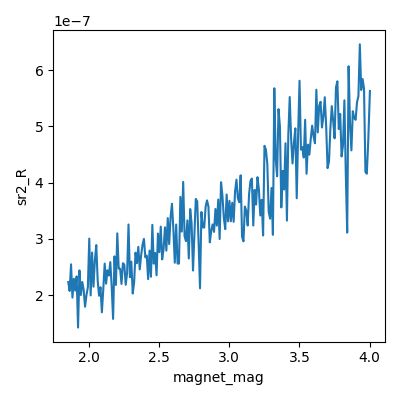

2026-06-19 03:15:50,612 [INFO] Completed in 0h 28m 59s


2026-06-19 03:15:50,612 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260619-QC0426\data\4\data.tsv.gz


spot A v3 done; B=1.850 T  T_end=1.199 K


In [27]:
import numpy as np, time
# --- preconditions: gates at hole density, magnet at 4 T ---
T0 = heater.sample_temperature()
print('pre: B=%.3f T  TG=%.3f BG=%.3f Si=%.3f  T=%.3f K' % (magnet.mag(), dc205.voltage(), k_2400.volt(), k_2410.volt(), T0))
assert abs(dc205.voltage()-(-4.666)) < 0.05 and abs(k_2400.volt()-(-3.616)) < 0.05, 'gates not at hole'
assert abs(k_2410.volt()) < 1e-6, 'Si not 0'
assert magnet.mag() > 3.9, 'expected magnet near 4 T for descending sweep'
# --- raise bias for SNR (tested: 4x current -> SNR 14-60, linear, no heating); rescale sens ---
sr1.amplitude(2.0); time.sleep(3)
sr0.sensitivity(5e-2); sr1.sensitivity(2e-6); sr2.sensitivity(2e-6); sr3.sensitivity(1e-5)
time.sleep(2)
meas_config['bias_voltage'] = sr1.amplitude()
for k,sr in [('sr0_sens',sr0),('sr1_sens',sr1),('sr2_sens',sr2),('sr3_sens',sr3)]:
    meas_config[k]=sr.sensitivity()
meas_config['comments'] = ('SdH spot-check HOLE n=-10e12 D=0 (2V bias=20nA, SNR-fixed); '
                           'B 4->0T dB=10mT; fp X/Y/R; T_start=%.3f K' % T0)
s = async_station(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(meas_config['comments'])
s.fp(magnet.mag); s.fp(k_2400.curr); s.fp(k_2410.curr); s.fp(sr0.X)
for sr in (sr1, sr2, sr3):
    s.fp(sr.X); s.fp(sr.Y); s.fp(sr.R)
s.plot(magnet.mag, sr2.R)
field = np.arange(4.0, 0.0 - 1e-9, -0.010)   # descending 4 -> 0 (reuse 4 T position)
s.sweep(magnet.mag, field, delay=0.5)
print('spot A v3 done; B=%.3f T  T_end=%.3f K' % (magnet.mag(), heater.sample_temperature()))


## HERA [E1] — SdH spot-check: HOLE n=−10e12, HIGH FIELD 2→8 T

data/2-4 established: SNR now good (20 nA), but **no SdH resolved below 4 T** (dRxx ≈
noise; FFT no peaks) — high onset from T_e≈8 K thermal/Dingle damping. Oscillation
amplitude grows with B, so push to the **8 T session cap** (investigation Step 6 regime).
B 2→8 T ascending, ΔB=15 mT (Nyquist down to ~2.1 T; high-field periods are long). Sens
rescaled up (5e-6 Rxx, 2e-5 Hall) for the MR rise + R_xy→~500 Ω at 8 T. ~67 min. Reads:
onset (where oscillations emerge above the 2.6 Ω noise) + tone content via 1/B FFT —
δF will be coarse (~8–15 T over the high-field window), enough for single-vs-split, the
fan refines. Ends at 8 T. Checkpoint ~33 min (B≈5 T). Auto: B≤8 T cap, gates in validators.
Tag `sdh-spot-check`.


In [28]:
import numpy as np, time
# --- preconditions: gates at hole density, magnet ~1.85 T, bias 2 V ---
T0 = heater.sample_temperature()
print('pre: B=%.3f T  TG=%.3f BG=%.3f Si=%.3f  bias=%.2f V  T=%.3f K' % (
    magnet.mag(), dc205.voltage(), k_2400.volt(), k_2410.volt(), sr1.amplitude(), T0))
assert abs(dc205.voltage()-(-4.666)) < 0.05 and abs(k_2400.volt()-(-3.616)) < 0.05, 'gates not at hole'
assert abs(k_2410.volt()) < 1e-6, 'Si not 0'
assert abs(sr1.amplitude()-2.0) < 0.01, 'bias not 2 V'
# sens rescaled for high-field MR rise (Rxx grows) + larger Hall at 8 T
sr1.sensitivity(5e-6); sr2.sensitivity(5e-6); sr3.sensitivity(2e-5)
time.sleep(2)
for k,sr in [('sr0_sens',sr0),('sr1_sens',sr1),('sr2_sens',sr2),('sr3_sens',sr3)]:
    meas_config[k]=sr.sensitivity()
meas_config['comments'] = ('SdH spot-check HOLE n=-10e12 D=0 HIGH-FIELD (20nA); B 2->8T dB=15mT; '
                           'SdH marginal <4T (T_e damping) -> push to 8T cap; onset+tones; T_start=%.3f K' % T0)
s = async_station(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(meas_config['comments'])
s.fp(magnet.mag); s.fp(k_2400.curr); s.fp(k_2410.curr); s.fp(sr0.X)
for sr in (sr1, sr2, sr3):
    s.fp(sr.X); s.fp(sr.Y); s.fp(sr.R)
s.plot(magnet.mag, sr2.R)
field = np.arange(2.0, 8.0 + 1e-9, 0.015)   # 2 -> 8 T ascending, 15 mT (401 pts)
s.sweep(magnet.mag, field, delay=0.5)
print('spot HF done; B=%.3f T  T_end=%.3f K' % (magnet.mag(), heater.sample_temperature()))


pre: B=1.853 T  TG=-4.666 BG=-3.616 Si=0.000  bias=2.00 V  T=1.198 K


2026-06-19 03:17:15,943 [INFO] Starting sweep with ID 5


2026-06-19 03:17:15,943 [INFO] Minimum duration 0h 3m 20s


ValueError: ('np.float64(8.00000000000005) is invalid: must be between -8.0 and 8.0 inclusive; Parameter: magnet.mag', 'setting magnet_mag to 8.00000000000005')

## HERA [E1] — pre-read for lower-density attempt (n=-5e12 @ 8 T)

n=-10e12 SdH resolution-limited even at 8 T. Test lower density (lighter mass -> lower
onset; larger Rxx) on the 8->0 descent (no-regret: magnet must come down). Ramp gates to
n=-5e12 D=0 (V_tg -2.337, V_bg -1.811); read Rxx/Hall magnitude at 8 T to pick sensitivity
before the descending sweep. Auto: gates in validators.

In [29]:
import time
VTG,VBG=-2.337,-1.811
s_dummy=None
print('before: B=%.3f TG=%.3f BG=%.3f'%(magnet.mag(),dc205.voltage(),k_2400.volt()))
dc205_volt(VTG); k_2400.volt(VBG); time.sleep(3)
Ib=sr1.amplitude()/100e6
print('at n=-5e12 D=0, B=%.3f T:'%magnet.mag())
print('  TG=%.3f BG=%.3f  I_drain=%.2f nA'%(dc205.voltage(),k_2400.volt(),sr0.X()/(-1e6)*1e9))
for nm,sr in [('sr1',sr1),('sr2',sr2),('sr3 Hall',sr3)]:
    print('  %s |R|=%.0f Ohm  (sens %.0e -> %.0f%%FS)'%(nm, sr.R()/Ib, sr.sensitivity(), sr.R()/sr.sensitivity()*100))

before: B=7.988 TG=-4.666 BG=-3.616


at n=-5e12 D=0, B=7.988 T:
  TG=-2.337 BG=-2.262  I_drain=19.81 nA
  sr1 |R|=211 Ohm  (sens 5e-06 -> 84%FS)


  sr2 |R|=273 Ohm  (sens 5e-06 -> 109%FS)
  sr3 Hall |R|=929 Ohm  (sens 2e-05 -> 93%FS)


## HERA [E1] — check BG gate settling / ramp config

BG read -2.262 V vs -1.811 V set — check if k_2400 is still ramping (slow background ramp)
or has a step/inter_delay, so I wait for gates before sweeping. Read-only.

In [30]:
import time
print('now: TG=%.4f BG=%.4f (target TG=-2.337 BG=-1.811)'%(dc205.voltage(),k_2400.volt()))
print('k_2400.volt.step=%s inter_delay=%s'%(getattr(k_2400.volt,'step',None), getattr(k_2400.volt,'inter_delay',None)))
time.sleep(3); print('after +3s: BG=%.4f'%k_2400.volt())
time.sleep(3); print('after +6s: BG=%.4f'%k_2400.volt())
Ib=sr1.amplitude()/100e6
print('Rxx now: sr1=%.0f sr2=%.0f Hall=%.0f Ohm'%(sr1.R()/Ib,sr2.R()/Ib,sr3.R()/Ib))

now: TG=-2.3370 BG=-2.0366 (target TG=-2.337 BG=-1.811)
k_2400.volt.step=0.005 inter_delay=0


after +3s: BG=-1.9238


after +6s: BG=-1.8674
Rxx now: sr1=214 sr2=273 Hall=938 Ohm


## HERA [E1] — SdH spot-check: HOLE n=−5e12 (lower density), descending 8→0 T

n=−10e12 was resolution-limited even at 8 T (SdH SNR ~1.5–2, no robust FFT tone). Test the
most promising lever — **lower density**: lighter cyclotron mass (m*∝√n) → larger ℏω_c → less
thermal damping → lower onset; and larger Rxx (~270 Ω) → bigger oscillation signal. Run on
the **mandatory 8→0 ramp-down** (no-regret). ΔB=20 mT (F_L=52 T → Nyquist to ~1.8 T). Sens
coarsened for the larger Rxx/Hall. Gates poll-verified settled (BG step-ramp + readback lag).
~81 min. Checkpoint ~25 min (B≈5 T). If clean oscillations appear → onset + tones → proceed;
if still marginal → strong evidence the device is resolution-limited on this rig (operator
consult on mK-rig / QH-Streda / accept). Auto: gates in validators, descending B. Tag `sdh-spot-check`.


gates settled in 3s: TG=-2.3370 BG=-1.8128


n=-5e12 @ 7.99T: I=19.69nA  sr1=219 sr2=294 Hall=994 Ohm
2026-06-19 04:33:50,183 [INFO] Starting sweep with ID 6


2026-06-19 04:33:50,184 [INFO] Minimum duration 0h 3m 20s


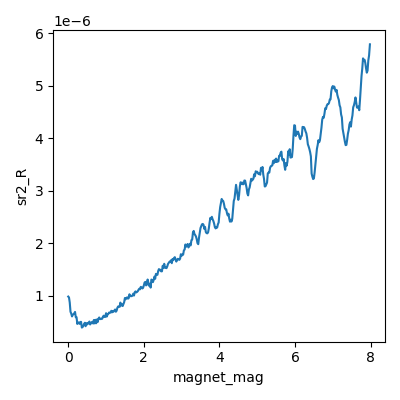

2026-06-19 05:56:39,993 [INFO] Completed in 1h 22m 48s


2026-06-19 05:56:39,993 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260619-QC0426\data\6\data.tsv.gz


lowdens spot done; B=-0.001 T  T_end=1.182 K


In [31]:
import numpy as np, time
# --- target lower density n=-5e12, D=0 (lighter mass -> lower onset; larger Rxx) ---
VTG, VBG = -2.337, -1.811
T0 = heater.sample_temperature()
assert magnet.mag() > 7.9, 'expected ~8 T for descending sweep'
assert abs(sr1.amplitude()-2.0) < 0.01 and abs(k_2410.volt()) < 1e-6
dc205_volt(VTG); k_2400.volt(VBG)
for w in range(25):                       # poll gate settling (BG step-ramps + readback lag)
    if abs(k_2400.volt()-VBG) < 0.005 and abs(dc205.voltage()-VTG) < 0.005: break
    time.sleep(1)
print('gates settled in %ds: TG=%.4f BG=%.4f' % (w, dc205.voltage(), k_2400.volt()))
# sens for large Rxx (~270 Ohm) + large Hall (~930 Ohm) at low n
sr1.sensitivity(2e-5); sr2.sensitivity(2e-5); sr3.sensitivity(5e-5); time.sleep(2)
Ib = sr1.amplitude()/100e6
print('n=-5e12 @ %.2fT: I=%.2fnA  sr1=%.0f sr2=%.0f Hall=%.0f Ohm' % (
    magnet.mag(), sr0.X()/(-1e6)*1e9, sr1.R()/Ib, sr2.R()/Ib, sr3.R()/Ib))
for k,sr in [('sr0_sens',sr0),('sr1_sens',sr1),('sr2_sens',sr2),('sr3_sens',sr3)]:
    meas_config[k]=sr.sensitivity()
meas_config['comments'] = ('SdH spot-check HOLE n=-5e12 D=0 (lower density, lighter mass; 20nA); '
                           'B 8->0T dB=20mT descending; test SdH resolvability; T_start=%.3f K' % T0)
s = async_station(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(meas_config['comments'])
s.fp(magnet.mag); s.fp(k_2400.curr); s.fp(k_2410.curr); s.fp(sr0.X)
for sr in (sr1, sr2, sr3):
    s.fp(sr.X); s.fp(sr.Y); s.fp(sr.R)
s.plot(magnet.mag, sr2.R)
field = np.arange(7.98, -0.001, -0.020)   # 8 -> 0 descending, 20 mT
s.sweep(magnet.mag, field, delay=0.5)
print('lowdens spot done; B=%.3f T  T_end=%.3f K' % (magnet.mag(), heater.sample_temperature()))


## HERA [E1] — BG set-blocking test (for fan retrace settling)

Time a large k_2400.volt set (1.5 V) to see if the call blocks until settled (step-ramp) or
returns early. Determines fan slow_delay / settling for the n-line retrace. Read-only timing.

In [32]:
import time
print('start BG=%.4f'%k_2400.volt())
t0=time.time(); k_2400.volt(-3.3); dt=time.time()-t0
print('set k_2400.volt(-3.3) returned after %.2f s; immediately reads %.4f'%(dt, k_2400.volt()))
time.sleep(0.5); print('after +0.5s: %.4f'%k_2400.volt())
t0=time.time(); k_2400.volt(-1.8); dt=time.time()-t0
print('set back to -1.8 returned after %.2f s; reads %.4f'%(dt,k_2400.volt()))

start BG=-1.8110


set k_2400.volt(-3.3) returned after 1.92 s; immediately reads -2.9278


after +0.5s: -3.1139


set back to -1.8 returned after 1.69 s; reads -2.0819


## HERA [E1] — Landau fan (Step 4): D=0, HOLE n=−3 to −6.5e12 × B 0→8 T

The decisive FS-count measurement (`landau-fan-vti`): F(n) across density to test the
Luttinger partition — does sr1's pair (f_ML+f_BL) sum to F_L(n) across density (real ABA),
and does sr2 stay single at F_L(n) (ABC)? Resolves the mosaic call. Spans the resolvable +
model-valid (|n|≤3.5e12 at the low end) hole window. B slow (blocking magnet, ramps once
0→8), n-line fast (co-swept dc205_volt + k_2400.volt along the calibrated D=0 line).

Design: 157 B-rows (40 mT above 2 T — Nyquist for F_L≲70 T; coarse below onset), 29 usable
n-points (Δn meets the LL ray-spacing floor). **col 0 is a throwaway** absorbing the per-row
n-line retrace (BG step-ramps slowly, no snake). Lock-ins pre-set (τ=0.1, sens 2e-5 Rxx /
1e-4 Hall — no autorange mid-fan); 20 nA. fp X/Y/R + leakage, no Lakeshore poll. ~2.5 h.

**Checkpoint ~70 min (B≈4 T):** per-row SdH emerging across the n-line? leakage clean? sens
not railing at low-n/high-B? Fork: continue / adjust / abort. Then per-column 1/B FFT →
F(n) → the call. Auto: gates in validators, B≤8 T cap. Tag `landau-fan-vti`.


fan: 157 B-rows x 30 n-pts (29 usable); B 0.0->8.0 T; n -3.0..-6.5 e12; T=1.167 K
2026-06-19 12:07:38,017 [INFO] Starting multimegasweep with ID 7


2026-06-19 12:07:38,018 [INFO] Minimum duration 0h 57m 34s


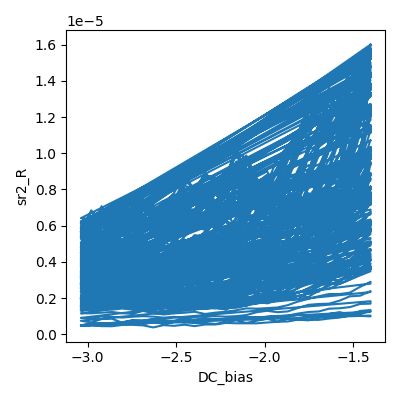

2026-06-19 14:43:07,859 [INFO] Completed in 2h 35m 28s


2026-06-19 14:43:07,860 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260619-QC0426\data\7\data.tsv.gz


2026-06-19 14:43:07,862 [INFO] Ramping DC_bias: -3.03875 -> 0.0


2026-06-19 14:43:09,547 [INFO] Ramping k_2400_volt: -2.343698 -> 0.0


fan done; B=8.003 T  T_end=1.274 K


In [33]:
import numpy as np, time
# --- preconditions ---
T0 = heater.sample_temperature()
assert abs(magnet.mag()) < 0.15, 'magnet not near 0 for ascending fan'
assert abs(sr1.amplitude()-2.0) < 0.01, 'bias not 2 V'
assert abs(k_2410.volt()) < 1e-6, 'Si not 0'
# --- lock-in setup BEFORE the fan (no autorange mid-fan); tau low for fast-gate settling ---
for sr in (sr1, sr2, sr3): sr.time_constant(0.1)
sr0.sensitivity(5e-2); sr1.sensitivity(2e-5); sr2.sensitivity(2e-5); sr3.sensitivity(1e-4)
time.sleep(2)
for k,sr in [('sr0_sens',sr0),('sr1_sens',sr1),('sr2_sens',sr2),('sr3_sens',sr3)]:
    meas_config[k]=sr.sensitivity()
# --- fast axis: D=0 n-line (cm^-2). Prepend throwaway pt to absorb the per-row BG retrace ---
K = 2.760e12          # dn/dV_bg along D=0 (cm^-2/V), from this session's calibration
ratio = 1.2903        # V_tg = ratio * V_bg on the D=0 line through CNP origin
ns = np.concatenate([[-3.0e12], np.linspace(-3.0e12, -6.5e12, 29)])   # col 0 = throwaway
Vbgs = ns / K
Vtgs = ratio * Vbgs
assert Vtgs.min() > -6 and Vtgs.max() < 7 and Vbgs.min() > -4.5 and Vbgs.max() < 4.5, 'gate line out of validators'
# --- slow axis: B, coarse below 2 T, fine (40 mT) above (Nyquist for F_L up to ~70 T) ---
B_vec = np.concatenate([np.linspace(0.0, 2.0, 6, endpoint=False), np.linspace(2.0, 8.0, 151)])
print('fan: %d B-rows x %d n-pts (29 usable); B %.1f->%.1f T; n %.1f..%.1f e12; T=%.3f K' % (
    len(B_vec), len(ns), B_vec.min(), B_vec.max(), ns.max()/1e12, ns.min()/1e12, T0))
meas_config['comments'] = ('landau-fan-vti D=0 HOLE n=-3..-6.5e12 x B 0->8T; FS-count F(n) partition '
                           '(sr2 single? sr1 pair sum F_L?); 20nA; col0 throwaway; T_start=%.3f K' % T0)
s = async_station(meas_config)
s.add_comment('landau-fan-vti')
s.add_comment(meas_config['comments'])
s.fp(magnet.mag); s.fp(k_2400.curr); s.fp(k_2410.curr); s.fp(sr0.X)
for sr in (sr1, sr2, sr3):
    s.fp(sr.X); s.fp(sr.Y); s.fp(sr.R)
s.plot(dc205_volt, sr2.R)
s.multimegasweep([magnet.mag], [B_vec], [dc205_volt, k_2400.volt], [Vtgs, Vbgs],
                 slow_delay=1.0, fast_delay=0.7)
s.ramp(dc205_volt, 0.0); s.ramp(k_2400.volt, 0.0)
print('fan done; B=%.3f T  T_end=%.3f K' % (magnet.mag(), heater.sample_temperature()))


## HERA [E1] — electron-side spot check (Step 3, both-signs), n=+5e12, 8->0 T

Closes the both-signs gap in the call. Mirror of the hole density that resolved cleanly
(n=+5e12, D=0). Reuses the 8 T position on the descent (no wasted ramp; parks at 0). 20nA,
sens 2e-5 Rxx / 1e-4 Hall. Confirms whether the single-tone-at-F_L (ABC) holds on the electron
side or differs. ~52 min. Tag sdh-spot-check.


In [ ]:
import numpy as np, time
# --- electron-side both-signs check (Step 3): n=+5e12, D=0; reuse 8 T on the descent ---
T0 = heater.sample_temperature()
assert magnet.mag() > 7.9, 'expected ~8 T for descending electron sweep'
assert abs(sr1.amplitude()-2.0) < 0.01 and abs(k_2410.volt()) < 1e-6
VTG, VBG = +2.337, +1.811           # n=+5e12 at D=0 (mirror of the hole point)
dc205_volt(VTG); k_2400.volt(VBG)
for w in range(25):
    if abs(k_2400.volt()-VBG) < 0.005 and abs(dc205.voltage()-VTG) < 0.005: break
    time.sleep(1)
sr1.sensitivity(2e-5); sr2.sensitivity(2e-5); sr3.sensitivity(1e-4); time.sleep(2)
Ib = sr1.amplitude()/100e6
print('gates settled %ds: TG=%.3f BG=%.3f | n=+5e12 @ %.2fT  I=%.2fnA  sr1=%.0f sr2=%.0f Hall=%.0f Ohm' % (
    w, dc205.voltage(), k_2400.volt(), magnet.mag(), sr0.X()/(-1e6)*1e9, sr1.R()/Ib, sr2.R()/Ib, sr3.R()/Ib))
for k,sr in [('sr0_sens',sr0),('sr1_sens',sr1),('sr2_sens',sr2),('sr3_sens',sr3)]:
    meas_config[k]=sr.sensitivity()
meas_config['comments'] = ('SdH spot-check ELECTRON n=+5e12 D=0 (both-signs check, Step 3); '
                           'B 8->0T dB=20mT descending; 20nA; T_start=%.3f K' % T0)
s = async_station(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(meas_config['comments'])
s.fp(magnet.mag); s.fp(k_2400.curr); s.fp(k_2410.curr); s.fp(sr0.X)
for sr in (sr1, sr2, sr3):
    s.fp(sr.X); s.fp(sr.Y); s.fp(sr.R)
s.plot(magnet.mag, sr2.R)
field = np.arange(7.98, -0.001, -0.020)   # 8 -> 0 descending, parks at 0
s.sweep(magnet.mag, field, delay=0.5)
print('electron spot done; B=%.3f T  T_end=%.3f K' % (magnet.mag(), heater.sample_temperature()))


gates settled 8s: TG=2.337 BG=1.809 | n=+5e12 @ 8.00T  I=19.83nA  sr1=504 sr2=340 Hall=895 Ohm
2026-06-19 14:46:34,163 [INFO] Starting sweep with ID 8


2026-06-19 14:46:34,164 [INFO] Minimum duration 0h 3m 20s


## HERA [E1] — session-end park + final state

Park gates to 0 (electron spot left them at n=+5e12); magnet already at 0. Confirm safe
resting state at end of the FS-count investigation.

In [35]:
import time
dc205_volt(0.0); k_2400.volt(0.0)
for w in range(20):
    if abs(dc205.voltage())<0.01 and abs(k_2400.volt())<0.01: break
    time.sleep(1)
print('PARKED: B=%.4f T  TG=%.3f  BG=%.3f  Si=%.3f  T=%.3f K' % (magnet.mag(), dc205.voltage(), k_2400.volt(), k_2410.volt(), heater.sample_temperature()))
print('magnet status:', magnet._status())

PARKED: B=0.0026 T  TG=0.000  BG=0.004  Si=0.000  T=1.179 K
magnet status: {'voltage': -0.0005771, 'field': 0.002607986301369863, 'output_enabled': True, 'persistent_switch_on': True, 'loop_mode': 'CC', 'update_mode': 'NORMAL'}


## HERA [E1] — readback: parked lock-in sensitivities / excitation / tau

Report the actual rest-state instrument settings (changed during the session from card defaults).

In [36]:
print('AC excitation (sr1.amplitude): %.3f V  -> I_bias = %.1f nA  (card default 0.5 V / 5 nA)' % (sr1.amplitude(), sr1.amplitude()/100e6*1e9))
print('lock-in sensitivity / time_constant / filter_slope:')
for nm,sr in [('sr0 (drain I)',sr0),('sr1 (Rxx T3-T4)',sr1),('sr2 (Rxx B4-B5)',sr2),('sr3 (Rxy Hall)',sr3)]:
    print('  %-16s sens=%-8.0e  tau=%.3f s  slope=%s dB/oct' % (nm, sr.sensitivity(), sr.time_constant(), sr.filter_slope()))

AC excitation (sr1.amplitude): 2.000 V  -> I_bias = 20.0 nA  (card default 0.5 V / 5 nA)
lock-in sensitivity / time_constant / filter_slope:
  sr0 (drain I)    sens=5e-02     tau=0.100 s  slope=24 dB/oct
  sr1 (Rxx T3-T4)  sens=2e-05     tau=0.100 s  slope=24 dB/oct
  sr2 (Rxx B4-B5)  sens=2e-05     tau=0.100 s  slope=24 dB/oct
  sr3 (Rxy Hall)   sens=1e-04     tau=0.100 s  slope=24 dB/oct


## HERA [E1] — restore card-default excitation (handoff)

Restore AC excitation to the device-card default 0.5 V (5 nA). Leave tau (0.1 s all) and
sensitivities as-is per operator. Device already parked (B=0, gates=0).

In [37]:
sr1.amplitude(0.5)
import time; time.sleep(1)
meas_config['bias_voltage']=sr1.amplitude()
print('excitation restored: sr1.amplitude=%.3f V -> I_bias=%.1f nA' % (sr1.amplitude(), sr1.amplitude()/100e6*1e9))
print('left unchanged: sens sr0=%.0e sr1=%.0e sr2=%.0e sr3=%.0e ; tau all=%.2f s' % (sr0.sensitivity(),sr1.sensitivity(),sr2.sensitivity(),sr3.sensitivity(),sr1.time_constant()))
print('park: B=%.4f T  TG=%.3f BG=%.3f Si=%.3f  T=%.3f K' % (magnet.mag(),dc205.voltage(),k_2400.volt(),k_2410.volt(),heater.sample_temperature()))

excitation restored: sr1.amplitude=0.500 V -> I_bias=5.0 nA
left unchanged: sens sr0=5e-02 sr1=2e-05 sr2=2e-05 sr3=1e-04 ; tau all=0.10 s


park: B=0.0026 T  TG=0.000 BG=0.002 Si=0.000  T=1.176 K
